# EDA: IEEE-CIS Fraud Detection
#### Лямкин Вячеслав
Одна строка — транзакция, `isFraud = 1` — метка мошенничества. Рассмотрим обучающие данные: сначала содержимое и качество данных, затем распределения и связь признаков с таргетом.


## 1. Знакомство с данными


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
transactions = pd.read_csv("data/raw/train_transaction.csv")
identity = pd.read_csv("data/raw/train_identity.csv")

print("Транзакции:", transactions.shape)
print("Identity:", identity.shape)


Транзакции: (590540, 394)
Identity: (144233, 41)


В identity заметно меньше строк. Таблицы связаны через `TransactionID`.Посмотрим, повторяются ли ключи.


In [3]:
print("Повторения ID в transactions:", transactions["TransactionID"].duplicated().sum())
print("Повторения ID в identity:", identity["TransactionID"].duplicated().sum())


Повторения ID в transactions: 0
Повторения ID в identity: 0


Ключи уникальны. Объединим таблицы через LEFT JOIN, чтобы сохранить все транзакции, в том числе без identity.


In [4]:
df = transactions.merge(identity, on="TransactionID", how="left")
print("После объединения:", df.shape)
df[["TransactionID", "isFraud", "TransactionAmt", "ProductCD"]].head()


После объединения: (590540, 434)


,TransactionID,isFraud,TransactionAmt,ProductCD
0,2987000,0,68.5,W
1,2987001,0,29.0,W
2,2987002,0,59.0,W
3,2987003,0,50.0,W
4,2987004,0,50.0,H


In [5]:
df["isFraud"].value_counts(dropna=False)


isFraud
0    569877
1     20663
Name: count, dtype: int64

В таргете только 0 и 1, пропусков нет. Единиц намного меньше — посчитаем их долю.


In [6]:
print("Мошеннические операции, %:", round(df["isFraud"].mean() * 100, 2))


Мошеннические операции, %: 3.5


**Вывод.** Получилось 590 540 транзакций и 432 признака (без учёта ID и таргета). Мошеннических операций всего 3,50%: при оценке модели нужно учитывать precision и recall, а не ограничиваться accuracy.


## 2. Основные статистики

Признаки карты и адреса, а также поля id_12–id_38 рассматриваем как категориальные (всего 49 категориальных признаков по информации с Kaggle), даже если они содержат числа. Обозначим это явно, чтобы не интерпретировать средние значения кодов категорий как содержательные характеристики; остальные текстовые поля pandas уже отличает от числовых.


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float64(399), int64(4), object(31)
memory usage: 1.9+ GB


In [8]:
codes = ["card1", "card2", "card3", "card5", "addr1", "addr2"]
codes += list(df.loc[:, "id_12":"id_38"].columns)
df[codes] = df[codes].astype("category")

cat_cols = df.select_dtypes(exclude="number").columns
num_cols = df.select_dtypes(include="number").columns.drop(["TransactionID", "isFraud", "TransactionDT"])

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: category(33), float64(382), int64(3), object(16)
memory usage: 1.8+ GB


Сохраним статистики всех признаков.


In [10]:
numeric_stats = df[num_cols].describe().T
numeric_stats.head(8).round(2)

,count,mean,std,min,25%,50%,75%,max
TransactionAmt,590540.0,135.03,239.16,0.25,43.32,68.77,125.0,31937.39
dist1,238269.0,118.50,371.87,0.00,3.00,8.00,24.0,10286.00
dist2,37627.0,231.86,529.05,0.00,7.00,37.00,206.0,11623.00
C1,590540.0,14.09,133.57,0.00,1.00,1.00,3.0,4685.00
C2,590540.0,15.27,154.67,0.00,1.00,1.00,3.0,5691.00
C3,590540.0,0.01,0.15,0.00,0.00,0.00,0.0,26.00
C4,590540.0,4.09,68.85,0.00,0.00,0.00,0.0,2253.00
C5,590540.0,5.57,25.79,0.00,0.00,0.00,1.0,349.00


In [11]:
category_stats = df[cat_cols].describe().T
category_stats.head(8)

,count,unique,top,freq
ProductCD,590540,5,W,439670
card1,590540,13553,7919,14932
card2,581607.0,500.0,321.0,48935.0
card3,588975.0,114.0,150.0,521287.0
card4,588963,4,visa,384767
card5,586281.0,119.0,226.0,296546.0
card6,588969,4,debit,439938
addr1,524834.0,332.0,299.0,46335.0


**Вывод.** Средняя сумма операции — 135,03, медиана — 68,77, максимум — 31 937,39. У распределения сумм длинный правый хвост: редкие крупные операции повышают среднее. Во многих столбцах `count` меньше числа строк — разберёмся с пропусками, прежде чем что-либо заполнять.


## 3. Пропуски

Посчитаем количество и процент пропусков по каждому входному признаку. Покажем десять столбцов с наибольшей долей пропусков; полная таблица останется в `missing`.


In [12]:
feature_cols = df.columns.drop(["TransactionID", "isFraud"])
missing = df[feature_cols].isna().sum().to_frame("count")
missing["percent"] = missing["count"] / len(df) * 100
missing.sort_values("percent", ascending=False).head(10).round(2)

,count,percent
id_24,585793,99.20
id_25,585408,99.13
id_07,585385,99.13
id_08,585385,99.13
id_21,585381,99.13
id_26,585377,99.13
id_23,585371,99.12
id_27,585371,99.12
id_22,585371,99.12
dist2,552913,93.63


In [13]:
missing_count = df[feature_cols].isna().sum(axis=1)
print("Пропущено ячеек:", missing["count"].sum())
print("Пропущено ячеек, %:", round(missing["percent"].mean(), 2))
print("Полностью заполненных строк:", (missing_count == 0).sum())


Пропущено ячеек: 115523073
Пропущено ячеек, %: 45.28
Полностью заполненных строк: 0


Теперь посмотрим на группы C, D, V и id целиком. Добавим число уникальных значений и сравним пропуски: `size` — число признаков в группе, `mean`, `min` и `max` — средний, минимальный и максимальный процент пропусков.


In [14]:
feature_review = missing.copy()
feature_review["unique"] = df[feature_cols].nunique()
feature_review["group"] = "Прочие"


In [15]:
feature_review.loc["C1":"C14", "group"] = "C"
feature_review.loc["D1":"D15", "group"] = "D"
feature_review.loc["V1":"V339", "group"] = "V"
feature_review.loc["id_01":"id_38", "group"] = "id"
feature_review.groupby("group")["percent"].agg(["size", "mean", "min", "max"]).round(2)


,size,mean,min,max
group,,,,
C,14,0.00,0.00,0.00
D,15,58.15,0.21,93.41
V,339,43.04,0.00,86.12
id,38,84.82,75.58,99.20
Прочие,26,33.72,0.00,93.63


**Вывод.** В C пропусков нет, в D их в среднем 58,15%, в V — 43,04%, в id — 84,82%. Внутри групп доли тоже заметно различаются, поэтому одинаково обрабатывать все признаки не стоит.


Проверим, нет ли признаков, у которых почти все значения одинаковые. Посчитаем долю самого частого значения среди заполненных строк (`most_common_percent`); `count` и `percent` здесь относятся к пропускам.


In [16]:
common_share = {}
for col in feature_cols:
    common_share[col] = df[col].value_counts(normalize=True).max() * 100
feature_review["most_common_percent"] = pd.Series(common_share)
feature_review.sort_values("most_common_percent", ascending=False).head(8).round(2)


,count,percent,unique,group,most_common_percent
V305,12,0.00,2,V,100.00
V1,279287,47.29,2,V,99.99
M1,271100,45.91,2,Прочие,99.99
V241,460110,77.91,5,V,99.97
V65,77096,13.06,2,V,99.97
V107,314,0.05,2,V,99.96
V14,76073,12.88,2,V,99.95
V68,77096,13.06,3,V,99.95


**Вывод.** V305, V1 и M1 почти не меняются; 100,00% у V305 получилось из-за округления. Пока оставим эти признаки: редкие значения и пропуски тоже могут быть связаны с таргетом.


Удаление строк с пропусками оставит пустую таблицу. Мы уже видели, что identity есть не для всех операций: проверим, зависит ли его наличие от продукта. В таблице ниже — проценты по каждому продукту, `True` означает наличие записи identity.


In [17]:
has_identity = df["TransactionID"].isin(identity["TransactionID"])
(pd.crosstab(df["ProductCD"], has_identity, normalize="index") * 100).round(1)

TransactionID,False,True
ProductCD,,
C,9.2,90.8
H,0.4,99.6
R,0.4,99.6
S,0.4,99.6
W,100.0,0.0


**Вывод.** Пропущено 45,28% ячеек, причём у продукта W нет ни одной записи identity. Это согласуется с различиями в сборе данных по продуктам; пропуски сохраним как информацию, а не будем удалять строки.


## 4. Связь категорий и таргета

Продукты различаются по наличию identity. Посмотрим, различается ли у них и доля мошенничества: `size` — число операций, `sum` — число мошеннических, `mean` — их доля от 0 до 1. Рассмотрим для примера категории `ProductCD`.


In [18]:
product = df.groupby("ProductCD")["isFraud"].agg(["size", "sum", "mean"])
product.round(3)


,size,sum,mean
ProductCD,,,
C,68519,8008,0.117
H,33024,1574,0.048
R,37699,1426,0.038
S,11628,686,0.059
W,439670,8969,0.020


У C доля мошенничества выше, хотя операций W намного больше. Покажем доли на графике.


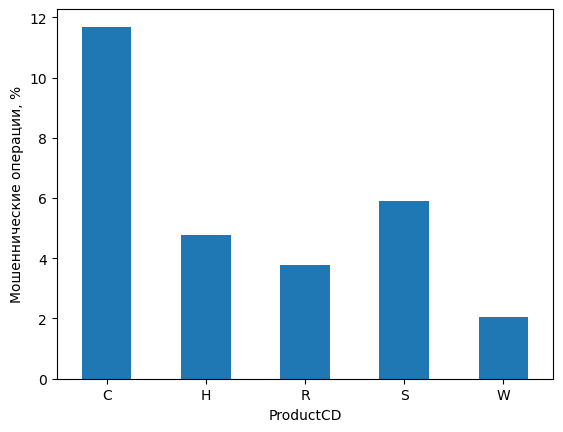

In [19]:
(product["mean"] * 100).plot.bar(rot=0)
plt.ylabel("Мошеннические операции, %")
plt.show()

Для остальных категориальных признаков повторяется тот же расчёт. Сохраним таблицы в словаре `category_risk` и для примера посмотрим тип карты `card6`.


In [20]:
category_risk = {}
for col in cat_cols:
    category_risk[col] = df.groupby(col, observed=True, dropna=False)["isFraud"].agg(["size", "sum", "mean"])

category_risk["card6"].round(3)


,size,sum,mean
card6,,,
charge card,15,0,0.000
credit,148986,9950,0.067
debit,439938,10674,0.024
debit or credit,30,0,0.000
NaN,1571,39,0.025


**Вывод.** Доля мошенничества у C — 11,69%, у W — 2,04%, но по числу таких операций W впереди: 8 969 против 8 008. У кредитных карт доля мошеннических операций выше, чем у дебетовых. Оценки для редких типов карт ненадёжны из-за малых групп.


Посмотрим, у каких признаков больше всего категорий. Затем сравним долю мошенничества по типу устройства `DeviceType`.


In [21]:
category_stats.sort_values("unique", ascending=False).head(5)


,count,unique,top,freq
card1,590540,13553,7919,14932
DeviceInfo,118666,1786,Windows,47722
id_19,139318.0,522.0,266.0,19849.0
card2,581607.0,500.0,321.0,48935.0
id_21,5159.0,490.0,252.0,2542.0


In [22]:
category_risk["DeviceType"].round(3)


,size,sum,mean
DeviceType,,,
desktop,85165,5554,0.065
mobile,55645,5657,0.102
NaN,449730,9452,0.021


**Вывод.** У card1 — 13 553 категории, у DeviceInfo — 1 786, поэтому нужно учитывать размеры групп. У категории `mobile` доля мошенничества 10,17%, у `desktop` — 6,52%, но это может быть связано и с разным составом продуктов.


## 5. Сумма операции

В статистиках был большой разрыв между медианой и максимумом суммы. Сначала проверим простые возможные ошибки; для анонимных признаков, которые невозможно интерпретировать, отрицательные значения могут быть допустимы (в отличие от суммы операции, например).


In [23]:
print("Пропуски ID:", df["TransactionID"].isna().sum())
print("Неположительные суммы:", (df["TransactionAmt"] <= 0).sum())
print("Бесконечности в числовых признаках:", np.isinf(df[num_cols]).sum().sum())

Пропуски ID: 0
Неположительные суммы: 0


Бесконечности в числовых признаках: 0


Эти проверки ошибок не выявили. Найдём границы выбросов суммы по правилу 1,5 IQR.


In [24]:
q1 = df["TransactionAmt"].quantile(0.25)
q3 = df["TransactionAmt"].quantile(0.75)
iqr = q3 - q1
print("Нижняя граница:", round(q1 - 1.5 * iqr, 2))
print("Верхняя граница:", round(q3 + 1.5 * iqr, 2))


Нижняя граница: -79.2
Верхняя граница: 247.52


Нижняя граница отрицательна, а все суммы положительные. Поэтому за границами, рассчитанными по правилу 1,5 IQR, находятся только операции с суммой выше примерно 247,52; сравним их с остальными.


In [25]:
outliers = df["TransactionAmt"] > q3 + 1.5 * iqr
print("Выбросы, %:", round(outliers.mean() * 100, 2))
df.groupby(outliers)["isFraud"].agg(["size", "sum", "mean"]).round(3)

Выбросы, %: 11.26


,size,sum,mean
TransactionAmt,,,
False,524058,17291,0.033
True,66482,3372,0.051


**Вывод.** По правилу 1,5 IQR к выбросам относятся 11,26% операций. Однако выход за эти границы не доказывает ошибку в данных, поэтому сохраним такие операции и рассмотрим распределение log(1 + TransactionAmt).


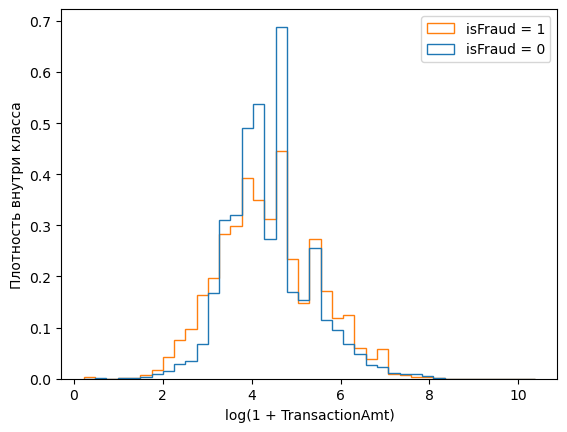

In [26]:
normal = np.log1p(df.loc[df["isFraud"] == 0, "TransactionAmt"])
fraud = np.log1p(df.loc[df["isFraud"] == 1, "TransactionAmt"])
plt.hist([normal, fraud], bins=40, density=True, histtype="step", label=["isFraud = 0", "isFraud = 1"])
plt.xlabel("log(1 + TransactionAmt)")
plt.ylabel("Плотность внутри класса")
plt.legend()
plt.show()

Гистограммы нормированы отдельно по классам: сравниваем форму распределений, а не число операций. Сопоставим медианы по таргету для всех числовых признаков; ниже — несколько примеров.


In [27]:
numeric_by_target = df.groupby("isFraud")[num_cols].median().T
numeric_by_target.loc[["TransactionAmt", "C1", "C13", "D1", "D15", "id_02"]]


isFraud,0,1
TransactionAmt,68.5,75.0
C1,1.0,2.0
C13,3.0,1.0
D1,4.0,0.0
D15,56.0,1.0
id_02,124125.0,149599.5


**Вывод.** Медиана суммы у мошеннических операций — 75, у остальных — 68,50, но распределения сильно перекрываются. Одной суммы недостаточно для разделения классов; посмотрим на связь других признаков с таргетом.


Одних медиан недостаточно, поэтому посмотрим на распределения C1, C13 и id_02. Для графиков снова используем log(1 + x), чтобы лучше видеть основную часть значений.


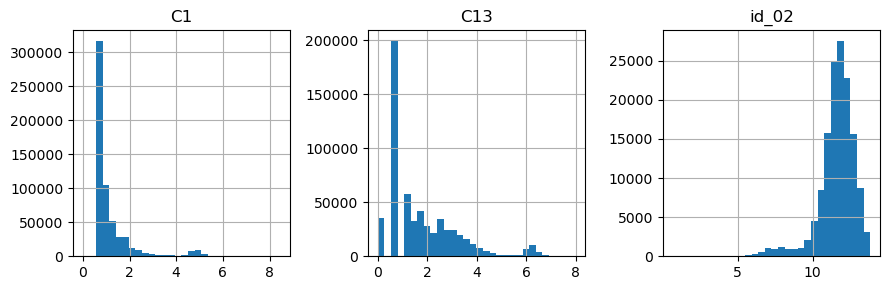

In [28]:
np.log1p(df[["C1", "C13", "id_02"]]).hist(bins=30, figsize=(9, 3), layout=(1, 3))
plt.tight_layout()
plt.show()


**Вывод.** У C1 и C13 много небольших значений и длинные правые хвосты. У id_02 много пропусков, поэтому график показывает только часть операций.


До этого выбросы проверяли только у суммы. Посчитаем их долю среди заполненных значений для всех числовых признаков; каждый столбец сравниваем со своими границами по правилу 1,5 IQR.

При IQR = 0 границы совпадают, и любое отличие от этого значения считается выбросом. Поэтому в итоговой таблице покажем признаки с IQR > 0, а для остальных будем смотреть на частоты значений.


In [29]:
iqr_all = numeric_stats["75%"] - numeric_stats["25%"]
lower = numeric_stats["25%"] - 1.5 * iqr_all
upper = numeric_stats["75%"] + 1.5 * iqr_all


In [30]:
outside = df[num_cols].lt(lower) | df[num_cols].gt(upper)
outlier_percent = outside.sum() / df[num_cols].count() * 100
print("Признаки с IQR = 0:", (iqr_all == 0).sum())
outlier_percent[iqr_all > 0].sort_values(ascending=False).head(10).round(2)


Признаки с IQR = 0: 302


D14      23.39
id_05    22.14
D12      21.24
V332     21.00
D6       20.26
V204     19.20
V265     19.04
D7       18.44
V203     18.41
V264     17.99
dtype: float64

**Вывод.** Выбросы по IQR есть не только у суммы: у D14 их 23,39%, у id_05 — 22,14% среди заполненных значений. Без описания этих полей не будем считать такие значения ошибками и удалять их.


## 6. Корреляции и парные распределения

Рассчитаем корреляцию каждого числового признака с таргетом и выберем пять наибольших по модулю. Пропуски исключаются при расчёте каждой пары; `count` покажет, на скольких наблюдениях получена оценка.


In [31]:
correlations = df[num_cols].corrwith(df["isFraud"])
top_features = correlations.abs().nlargest(5).index
top = correlations[top_features].to_frame("correlation")
top["count"] = df[top_features].count()
top.round(3)

,correlation,count
V257,0.383,130430
V246,0.367,130430
V244,0.364,130430
V242,0.361,130430
V201,0.328,139819


Вверху списка оказались признаки V, заполненные лишь для части транзакций. Посмотрим, насколько они связаны между собой: высокая связь с таргетом ещё не означает, что каждый признак несёт отдельную информацию.


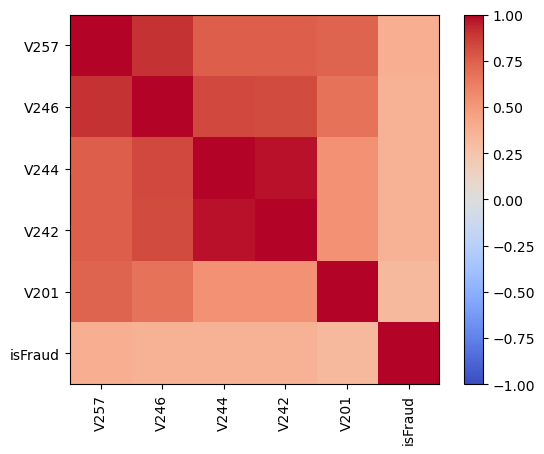

In [32]:
columns = list(top_features) + ["isFraud"]
corr = df[columns].corr()
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(columns)), columns, rotation=90)
plt.yticks(range(len(columns)), columns)
plt.colorbar()
plt.show()

На карте корреляций заметна сильная связь V244 с V242. Сравним их парные распределения вместе с V257 на 3 000 строк без пропусков в этих трёх полях; выборка нужна только для графика.


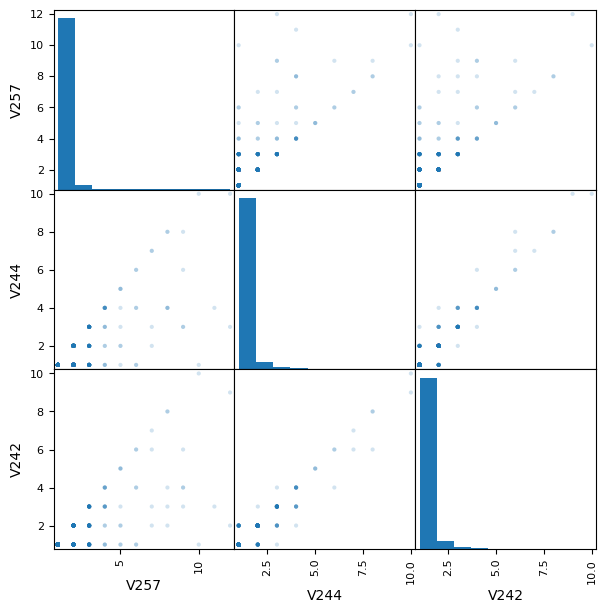

In [33]:
sample = df[["V257", "V244", "V242"]].dropna().sample(3000, random_state=42)
pd.plotting.scatter_matrix(sample, figsize=(7, 7), diagonal="hist", alpha=0.2)
plt.show()

In [ ]:
print(round(df["V244"].corr(df["V242"]), 3))

0.974


**Вывод.** У V257 корреляция с таргетом равна 0,383 на 130 430 непустых значениях; у пары V244–V242 она достигает 0,974. Это повод проверить избыточность признаков, но корреляция не доказывает причинность и не заменяет оценку модели.


До этого смотрели только на признаки с наибольшей корреляцией с таргетом. Теперь проверим корреляции между всеми числовыми признаками: сильная связь может быть и у других пар.


In [ ]:
all_corr = df[num_cols].corr()

Переведём матрицу в список пар через `stack`. Уберём диагональ и повторы: условие `feature_1 < feature_2` оставляет каждую пару только один раз.


In [ ]:
pairs = all_corr.stack(future_stack=True).reset_index()
pairs.columns = ["feature_1", "feature_2", "correlation"]
pairs = pairs[pairs["feature_1"] < pairs["feature_2"]]
top_pairs = pairs.loc[pairs["correlation"].abs().nlargest(10).index].copy()

Корреляции посчитаны только по заполненным парам значений. Добавим число таких наблюдений, чтобы было видно, на каком количестве операций получен результат.


In [37]:
for i in top_pairs.index:
    col1 = top_pairs.loc[i, "feature_1"]
    col2 = top_pairs.loc[i, "feature_2"]
    top_pairs.loc[i, "count"] = df[[col1, col2]].dropna().shape[0]
top_pairs.round(3)


,feature_1,feature_2,correlation,count
10716,D12,D4,1.000,64324.0
134972,V322,V95,1.000,82351.0
135355,V323,V96,1.000,82351.0
135738,V324,V97,1.000,82351.0
50777,V101,V322,1.000,82351.0
118773,V279,V322,1.000,82351.0
50550,V101,V95,1.000,590226.0
118744,V279,V293,1.000,590528.0
5357,C12,C7,0.999,590540.0
119157,V280,V324,0.999,82351.0


**Вывод.** Сильная связь есть и у других пар: у D12 и D4 корреляция почти 1 на 64 324 совместно заполненных строках. При моделировании стоит проверить, достаточно ли одного из этих признаков; сама корреляция не доказывает, что столбцы полностью совпадают.


Добавим корреляции с таргетом в общую таблицу `feature_review`. Сводные статистики числовых признаков уже есть в `numeric_stats`, медианы по классам — в `numeric_by_target`, а таблицы по категориям — в `category_risk`.


In [ ]:
feature_review["correlation"] = correlations
feature_review.loc[["C1", "D15", "V257", "id_02"]].round(3)

,count,percent,unique,group,most_common_percent,correlation
C1,0,0.000,1657,C,53.644,0.031
D15,89113,15.090,859,D,34.750,-0.078
V257,460110,77.913,49,V,88.810,0.383
id_02,449668,76.145,115655,id,0.008,0.049


**Вывод.** Для всех признаков посчитаны пропуски, число уникальных значений и доля самого частого значения. Связь с таргетом тоже рассмотрена, но низкая корреляция сама по себе не означает, что признак бесполезен.


## 7. Изменения во времени

До этого мы рассматривали данные за весь период наблюдения вместе. Проверим, постоянна ли доля мошенничества: `TransactionDT` — относительное время в секундах; разделим его на четыре равных по длительности периода.


In [39]:
period = pd.cut(df["TransactionDT"], 4, labels=[1, 2, 3, 4])
time_stats = df.groupby(period, observed=True)["isFraud"].agg(["size", "mean"])
time_stats.round(3)

,size,mean
TransactionDT,,
1,181596,0.029
2,138331,0.041
3,141790,0.038
4,128823,0.034


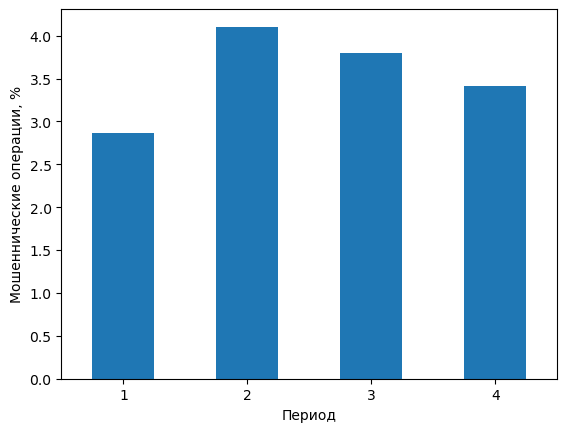

In [40]:
(time_stats["mean"] * 100).plot.bar(rot=0)
plt.xlabel("Период")
plt.ylabel("Мошеннические операции, %")
plt.show()

**Вывод.** Доля мошенничества меняется: 2,87%, 4,10%, 3,80% и 3,41% по периодам. Закономерности, найденные на прошлых операциях, нужно проверять на последующем временном отрезке.


## 8. Решения по обработке данных

В каждой транзакции есть хотя бы один пропуск, поэтому удаление неполных строк оставит пустую таблицу. Результат обработки сохраним в отдельной таблице `prepared`, чтобы исходная `df` оставалась доступна для сравнения.

Сначала добавим `missing_count` — количество незаполненных исходных признаков у каждой транзакции. Эти значения уже посчитаны в разделе 3, до замены пропусков; такой признак позволит проверить, связана ли неполнота данных с мошенничеством.


In [41]:
prepared = df.copy()
prepared["missing_count"] = missing_count
prepared[["missing_count"]].head()

,missing_count
0,234
1,230
2,211
3,227
4,137


Теперь заменим пропуски в категориальных признаках на `Missing` — «значение неизвестно».


In [42]:
prepared[cat_cols] = prepared[cat_cols].astype("string").fillna("Missing")
print("Пропусков в категориях:", prepared[cat_cols].isna().sum().sum())
print("Пропусков в числовых признаках:", prepared[num_cols].isna().sum().sum())
print("Транзакций после обработки:", len(prepared))

Пропусков в категориях: 0


Пропусков в числовых признаках: 97719626
Транзакций после обработки: 590540


**Числовые пропуски пока оставляем.** Отсутствие значения не означает ноль. Если выбранная модель потребует заполнения, сначала разделим данные на более ранний обучающий и более поздний проверочный периоды, затем рассчитаем медианы на обучающей части и заполним пропуски.

**Выбросы суммы сохраняем.** Правило IQR выделило 11,26% операций, но большая сумма сама по себе не доказывает ошибку; среди этих операций есть мошеннические. В разделе 5 логарифм использовался только для графика, поэтому исходные суммы в таблице не изменились.

**Вывод.** В таблице `prepared` категориальные пропуски обозначены как `Missing`, а исходное количество пропусков сохранено в `missing_count`. Все 590 540 транзакций, числовые пропуски и суммы операций сохранены; таблица `df` не изменена.
